## Pregunta 2 — Compresión HDR y recuperación de color

### Importaciones

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from zipfile import ZipFile
from io import BytesIO
import cv2
import p2

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 8)

In [76]:
import importlib
importlib.reload(p2)

<module 'p2' from 'c:\\Users\\apfib\\OneDrive\\Desktop\\IEE2714\\t4-IEE2714\\p2.py'>

### Carga de Imágenes de Alto Rango Dinámico (HDR)
Cargamos dos imágenes RGB HDR entregadas

Imagen 1 (belgium.hdr) - Rango: [0.00, 0.65] - Dim: (769, 1025, 3)
Imagen 2 (memorial.hdr) - Rango: [0.00, 274.00] - Dim: (768, 512, 3)


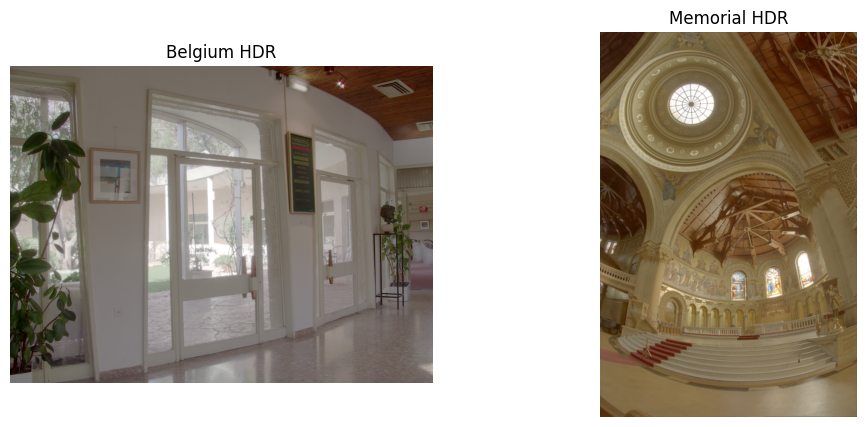

In [77]:
img1_hdr = p2.cargar_img('belgium.hdr', zip_path='archivos_t4.zip')
img2_hdr = p2.cargar_img('memorial.hdr', zip_path='archivos_t4.zip')

print(f"Imagen 1 (belgium.hdr) - Rango: [{img1_hdr.min():.2f}, {img1_hdr.max():.2f}] - Dim: {img1_hdr.shape}")
print(f"Imagen 2 (memorial.hdr) - Rango: [{img2_hdr.min():.2f}, {img2_hdr.max():.2f}] - Dim: {img2_hdr.shape}")

# Visualización preliminar con reescalamiento logarítmico para vista previa
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(p2.reescalar(np.log10(img1_hdr + 1e-6)))
axs[0].set_title('Belgium HDR')
axs[0].axis('off')

axs[1].imshow(p2.reescalar(np.log10(img2_hdr + 1e-6)))
axs[1].set_title('Memorial HDR')
axs[1].axis('off')
plt.show()

### Extracción y Compresión de Luminancia (Filtro Homomórfico vs Durand)
Extraemos la luminancia y aplicamos ambos algoritmos.

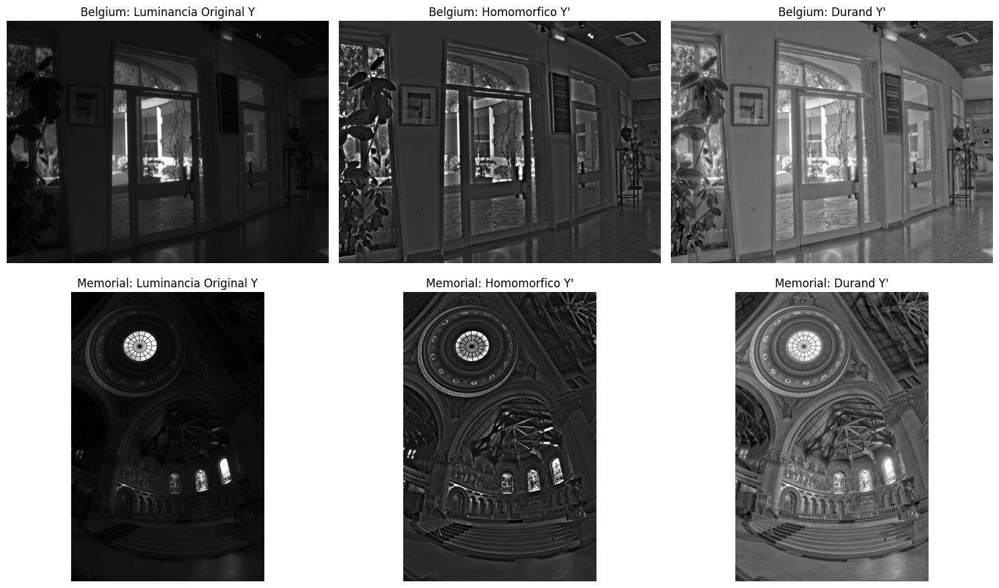

In [78]:
# Procesamiento de Luminancia para Imagen 1 (Belgium)
Y1 = p2.luminancia(img1_hdr)
Y1_homo = p2.filtro_homomorfico(Y1, gamma_H=1.5, gamma_L=0.25, D0=40, c=1.0)
Y1_durand = p2.durand_hdr(Y1, sigma_r=0.4, contraste=30)

# Procesamiento de Luminancia para Imagen 2 (Memorial)
Y2 = p2.luminancia(img2_hdr)
Y2_homo = p2.filtro_homomorfico(Y2, gamma_H=1.5, gamma_L=0.25, D0=40, c=1.0)
Y2_durand = p2.durand_hdr(Y2, sigma_r=0.4, contraste=30)

fig, axs = plt.subplots(2, 3, figsize=(15, 9))
axs[0, 0].imshow(p2.a_pantalla(p2.reescalar(Y1)), cmap="gray")
axs[0, 0].set_title("Belgium: Luminancia Original Y")
axs[0, 0].axis("off")

axs[0, 1].imshow(p2.a_pantalla(Y1_homo), cmap="gray")
axs[0, 1].set_title("Belgium: Homomorfico Y'")
axs[0, 1].axis("off")

axs[0, 2].imshow(p2.a_pantalla(Y1_durand), cmap="gray")
axs[0, 2].set_title("Belgium: Durand Y'")
axs[0, 2].axis("off")

axs[1, 0].imshow(p2.a_pantalla(p2.reescalar(Y2)), cmap="gray")
axs[1, 0].set_title("Memorial: Luminancia Original Y")
axs[1, 0].axis("off")

axs[1, 1].imshow(p2.a_pantalla(Y2_homo), cmap="gray")
axs[1, 1].set_title("Memorial: Homomorfico Y'")
axs[1, 1].axis("off")

axs[1, 2].imshow(p2.a_pantalla(Y2_durand), cmap="gray")
axs[1, 2].set_title("Memorial: Durand Y'")
axs[1, 2].axis("off")

plt.tight_layout()
plt.show()

### Aplicacion en canales RGB
Aplicamos la compresión de canal independiente para observar las distorsiones de color y tono.

=== MÉTRICAS DE COMPRESIÓN CANAL RGB INDEPENDIENTE (Belgium) ===
Homomórfico Indep. - Croma Orig/Proc: 181.58 / 181.52 | Cambio Tono (Hue Shift): 42.84°
Durand Indep.      - Croma Orig/Proc: 181.58 / 170.77 | Cambio Tono (Hue Shift): 148.08°


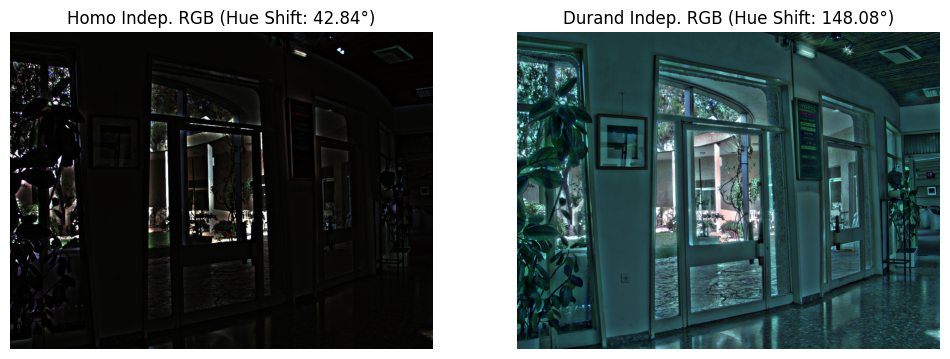

In [79]:
# Compresión por canal separado
indep_homo1 = p2.compresion_rgb_independiente(img1_hdr, metodo='homomorfico')
indep_durand1 = p2.compresion_rgb_independiente(img1_hdr, metodo='durand')

m_indep_homo = p2.calculate_color_metrics(img1_hdr, indep_homo1)
m_indep_durand = p2.calculate_color_metrics(img1_hdr, indep_durand1)

print("=== MÉTRICAS DE COMPRESIÓN CANAL RGB INDEPENDIENTE (Belgium) ===")
print(f"Homomórfico Indep. - Croma Orig/Proc: {m_indep_homo['chroma_orig']} / {m_indep_homo['chroma_proc']} | Cambio Tono (Hue Shift): {m_indep_homo['hue_shift_deg']}°")
print(f"Durand Indep.      - Croma Orig/Proc: {m_indep_durand['chroma_orig']} / {m_indep_durand['chroma_proc']} | Cambio Tono (Hue Shift): {m_indep_durand['hue_shift_deg']}°")

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(indep_homo1)
axs[0].set_title(f'Homo Indep. RGB (Hue Shift: {m_indep_homo["hue_shift_deg"]}°)')
axs[0].axis('off')

axs[1].imshow(indep_durand1)
axs[1].set_title(f'Durand Indep. RGB (Hue Shift: {m_indep_durand["hue_shift_deg"]}°)')
axs[1].axis('off')
plt.show()

=== MÉTRICAS DE COMPRESIÓN CANAL RGB INDEPENDIENTE (Belgium) ===
Homomórfico Indep. - Croma Orig/Proc: 181.56 / 182.29 | Cambio Tono (Hue Shift): 25.78°
Durand Indep.      - Croma Orig/Proc: 181.56 / 176.32 | Cambio Tono (Hue Shift): 119.88°


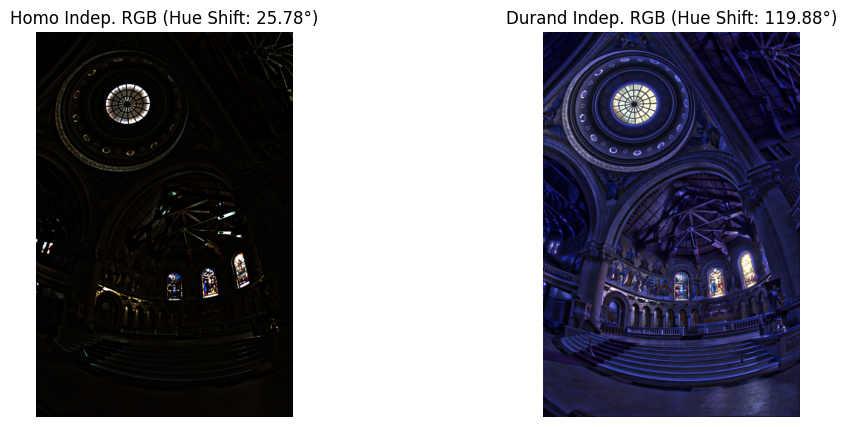

In [80]:
# Compresión por canal separado
indep_homo1 = p2.compresion_rgb_independiente(img2_hdr, metodo='homomorfico')
indep_durand1 = p2.compresion_rgb_independiente(img2_hdr, metodo='durand')

m_indep_homo = p2.calculate_color_metrics(img2_hdr, indep_homo1)
m_indep_durand = p2.calculate_color_metrics(img2_hdr, indep_durand1)

print("=== MÉTRICAS DE COMPRESIÓN CANAL RGB INDEPENDIENTE (Belgium) ===")
print(f"Homomórfico Indep. - Croma Orig/Proc: {m_indep_homo['chroma_orig']} / {m_indep_homo['chroma_proc']} | Cambio Tono (Hue Shift): {m_indep_homo['hue_shift_deg']}°")
print(f"Durand Indep.      - Croma Orig/Proc: {m_indep_durand['chroma_orig']} / {m_indep_durand['chroma_proc']} | Cambio Tono (Hue Shift): {m_indep_durand['hue_shift_deg']}°")

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(indep_homo1)
axs[0].set_title(f'Homo Indep. RGB (Hue Shift: {m_indep_homo["hue_shift_deg"]}°)')
axs[0].axis('off')

axs[1].imshow(indep_durand1)
axs[1].set_title(f'Durand Indep. RGB (Hue Shift: {m_indep_durand["hue_shift_deg"]}°)')
axs[1].axis('off')
plt.show()

Cambia el tono completamente en duran y en homorfico se oscurece

## Experimentación y análisis

### 1. Estrategia 1 de Color: Razón de Luminancia con Exponente $\beta$
Evaluamos $C' = Y' \cdot \left(\frac{C}{Y + \varepsilon}\right)^\beta$ para $\beta \in [0.5, 1.0, 1.5]$.

=== ESTRATEGIA 1: RAZÓN DE LUMINANCIA (BELGIUM) ===
Beta = 0.5 | Homo  - Croma: 183.31 | Hue Shift: 25.21°
Beta = 0.5 | Durand - Croma: 185.09 | Hue Shift: 25.24°
Beta = 1.0 | Homo  - Croma: 185.66 | Hue Shift: 24.86°
Beta = 1.0 | Durand - Croma: 189.42 | Hue Shift: 24.89°
Beta = 1.5 | Homo  - Croma: 188.07 | Hue Shift: 24.54°
Beta = 1.5 | Durand - Croma: 193.91 | Hue Shift: 24.57°


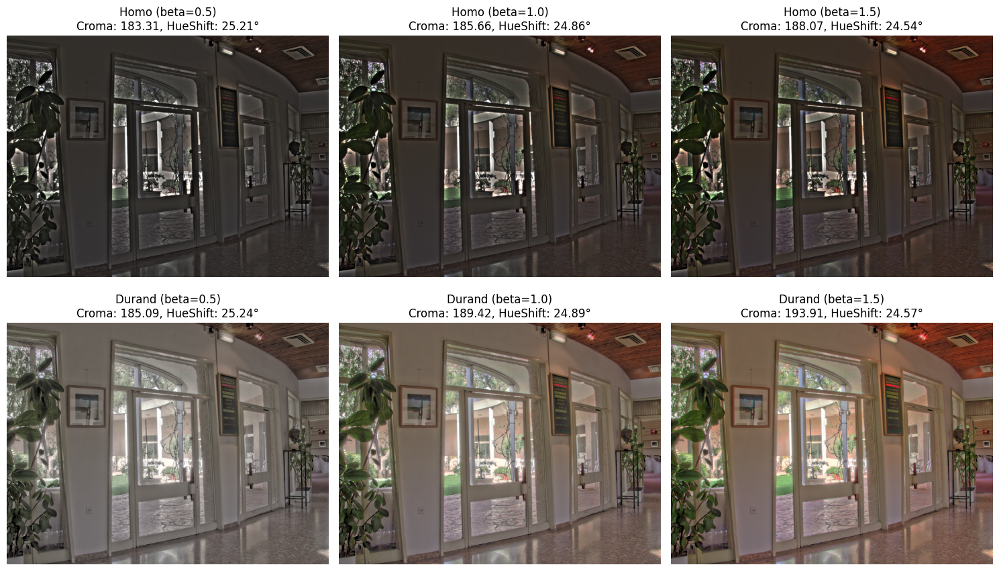

In [81]:
betas = [0.5, 1.0, 1.5]

# Prueba sobre Belgium con Homomórfico y Durand
fig, axs = plt.subplots(2, 3, figsize=(15, 9))

print("=== ESTRATEGIA 1: RAZÓN DE LUMINANCIA (BELGIUM) ===")
for idx, b in enumerate(betas):
    rec_homo = p2.reconstruct_color_ratio(img1_hdr, Y1, Y1_homo, beta=b)
    m_h = p2.calculate_color_metrics(img1_hdr, rec_homo)
    
    rec_dur = p2.reconstruct_color_ratio(img1_hdr, Y1, Y1_durand, beta=b)
    m_d = p2.calculate_color_metrics(img1_hdr, rec_dur)
    
    print(f"Beta = {b:.1f} | Homo  - Croma: {m_h['chroma_proc']} | Hue Shift: {m_h['hue_shift_deg']}°")
    print(f"Beta = {b:.1f} | Durand - Croma: {m_d['chroma_proc']} | Hue Shift: {m_d['hue_shift_deg']}°")
    
    axs[0, idx].imshow(rec_homo)
    axs[0, idx].set_title(f'Homo (beta={b})\nCroma: {m_h["chroma_proc"]}, HueShift: {m_h["hue_shift_deg"]}°')
    axs[0, idx].axis('off')
    
    axs[1, idx].imshow(rec_dur)
    axs[1, idx].set_title(f'Durand (beta={b})\nCroma: {m_d["chroma_proc"]}, HueShift: {m_d["hue_shift_deg"]}°')
    axs[1, idx].axis('off')

plt.tight_layout()
plt.show()

=== ESTRATEGIA 1: RAZÓN DE LUMINANCIA (MEMORIAL) ===
Beta = 0.5 | Homo  - Croma: 188.14 | Hue Shift: 26.66°
Beta = 0.5 | Durand - Croma: 194.86 | Hue Shift: 26.58°
Beta = 1.0 | Homo  - Croma: 195.05 | Hue Shift: 23.26°
Beta = 1.0 | Durand - Croma: 208.56 | Hue Shift: 23.22°
Beta = 1.5 | Homo  - Croma: 201.65 | Hue Shift: 20.18°
Beta = 1.5 | Durand - Croma: 221.43 | Hue Shift: 20.15°


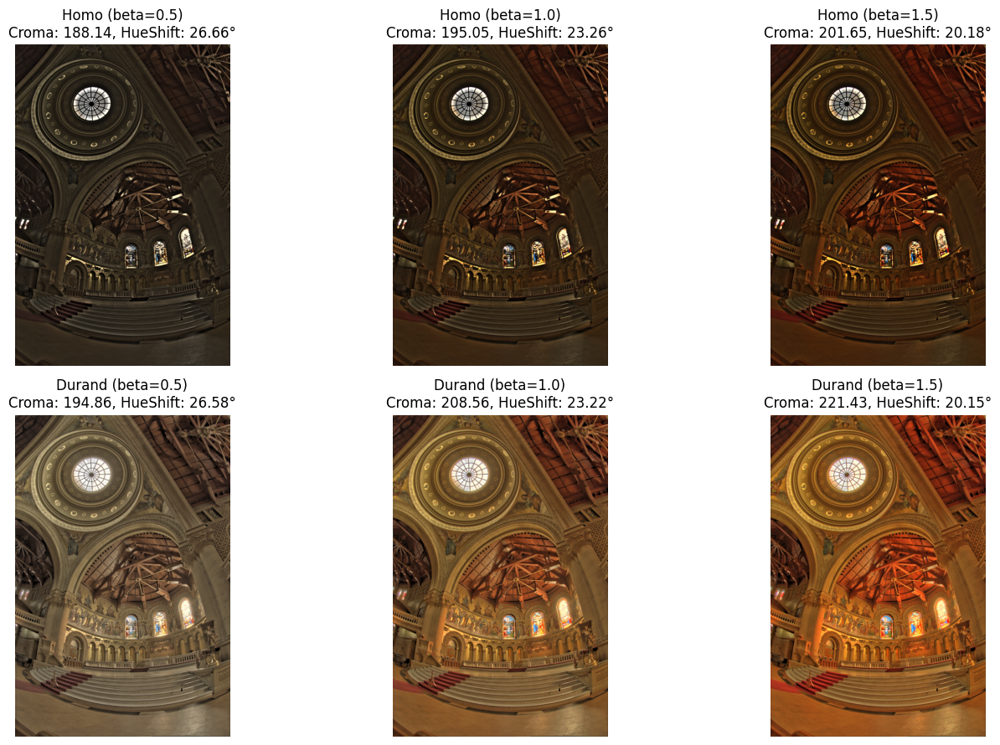

In [82]:
betas = [0.5, 1.0, 1.5]

# Prueba sobre Belgium con Homomórfico y Durand
fig, axs = plt.subplots(2, 3, figsize=(15, 9))

print("=== ESTRATEGIA 1: RAZÓN DE LUMINANCIA (MEMORIAL) ===")
for idx, b in enumerate(betas):
    rec_homo = p2.reconstruct_color_ratio(img2_hdr, Y2, Y2_homo, beta=b)
    m_h = p2.calculate_color_metrics(img2_hdr, rec_homo)
    
    rec_dur = p2.reconstruct_color_ratio(img2_hdr, Y2, Y2_durand, beta=b)
    m_d = p2.calculate_color_metrics(img2_hdr, rec_dur)
    
    print(f"Beta = {b:.1f} | Homo  - Croma: {m_h['chroma_proc']} | Hue Shift: {m_h['hue_shift_deg']}°")
    print(f"Beta = {b:.1f} | Durand - Croma: {m_d['chroma_proc']} | Hue Shift: {m_d['hue_shift_deg']}°")
    
    axs[0, idx].imshow(rec_homo)
    axs[0, idx].set_title(f'Homo (beta={b})\nCroma: {m_h["chroma_proc"]}, HueShift: {m_h["hue_shift_deg"]}°')
    axs[0, idx].axis('off')
    
    axs[1, idx].imshow(rec_dur)
    axs[1, idx].set_title(f'Durand (beta={b})\nCroma: {m_d["chroma_proc"]}, HueShift: {m_d["hue_shift_deg"]}°')
    axs[1, idx].axis('off')

plt.tight_layout()
plt.show()

Esta estrategia preserva la dirección del vector cromático original ($C/Y$), evitando el viraje de tono (hue shift):
- $\beta = 0.5$: Desatura la imagen (tonos suaves/pasteles).
- $\beta = 1.0$: Mantiene la cromaticidad relativa original.
- $\beta = 1.5$: Amplifica la saturación en sombras comprimidas.

El filtro homomórfico muestra una menor saturación de color y presenta halos/líneas oscuras alrededor de los bordes de alto contraste debido a la atenuación frecuencial.

### 2. Estrategia 2 de Color: Ajuste en Espacio HSV ($S' = s_{factor} \cdot S$)
Evaluamos la reconstrucción en HSV para factores $s_{factor} \in [0.5, 1.0, 1.5]$.

=== ESTRATEGIA 2: AJUSTE DE SATURACIÓN EN HSV (BELGIUM) ===
s_factor = 0.5 | Homo   - Croma: 183.01 | Hue Shift: 22.98°
s_factor = 0.5 | Durand - Croma: 183.08 | Hue Shift: 32.41°
s_factor = 1.0 | Homo   - Croma: 184.23 | Hue Shift: 27.14°
s_factor = 1.0 | Durand - Croma: 185.45 | Hue Shift: 33.55°
s_factor = 1.5 | Homo   - Croma: 185.64 | Hue Shift: 29.54°
s_factor = 1.5 | Durand - Croma: 188.64 | Hue Shift: 34.24°


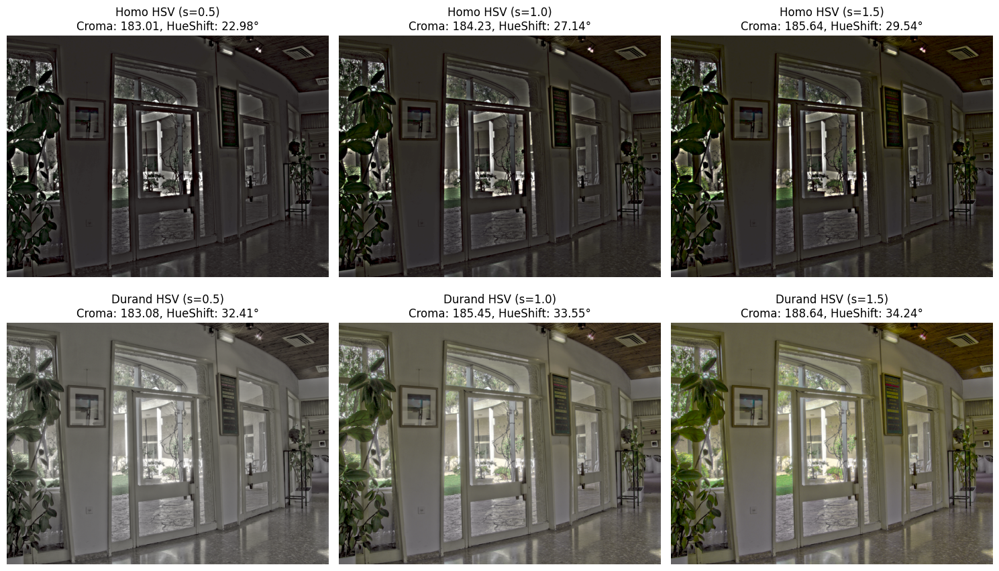

In [83]:
s_factors = [0.5, 1.0, 1.5]

fig, axs = plt.subplots(2, 3, figsize=(15, 9))
print("=== ESTRATEGIA 2: AJUSTE DE SATURACIÓN EN HSV (BELGIUM) ===")
for idx, sf in enumerate(s_factors):
    rec_hsv_h = p2.reconstruct_color_hsv(img1_hdr, Y1_homo, s_factor=sf)
    m_h = p2.calculate_color_metrics(img1_hdr, rec_hsv_h)
    
    rec_hsv_d = p2.reconstruct_color_hsv(img1_hdr, Y1_durand, s_factor=sf)
    m_d = p2.calculate_color_metrics(img1_hdr, rec_hsv_d)
    
    print(f"s_factor = {sf:.1f} | Homo   - Croma: {m_h['chroma_proc']} | Hue Shift: {m_h['hue_shift_deg']}°")
    print(f"s_factor = {sf:.1f} | Durand - Croma: {m_d['chroma_proc']} | Hue Shift: {m_d['hue_shift_deg']}°")
    
    axs[0, idx].imshow(rec_hsv_h)
    axs[0, idx].set_title(f'Homo HSV (s={sf})\nCroma: {m_h["chroma_proc"]}, HueShift: {m_h["hue_shift_deg"]}°')
    axs[0, idx].axis('off')
    
    axs[1, idx].imshow(rec_hsv_d)
    axs[1, idx].set_title(f'Durand HSV (s={sf})\nCroma: {m_d["chroma_proc"]}, HueShift: {m_d["hue_shift_deg"]}°')
    axs[1, idx].axis('off')

plt.tight_layout()
plt.show()

=== ESTRATEGIA 2: AJUSTE DE SATURACIÓN EN HSV (MEMORIAL) ===
s_factor = 0.5 | Homo   - Croma: 185.4 | Hue Shift: 19.22°
s_factor = 0.5 | Durand - Croma: 187.02 | Hue Shift: 35.15°
s_factor = 1.0 | Homo   - Croma: 190.26 | Hue Shift: 30.69°
s_factor = 1.0 | Durand - Croma: 196.98 | Hue Shift: 39.54°
s_factor = 1.5 | Homo   - Croma: 192.88 | Hue Shift: 31.08°
s_factor = 1.5 | Durand - Croma: 207.77 | Hue Shift: 42.38°


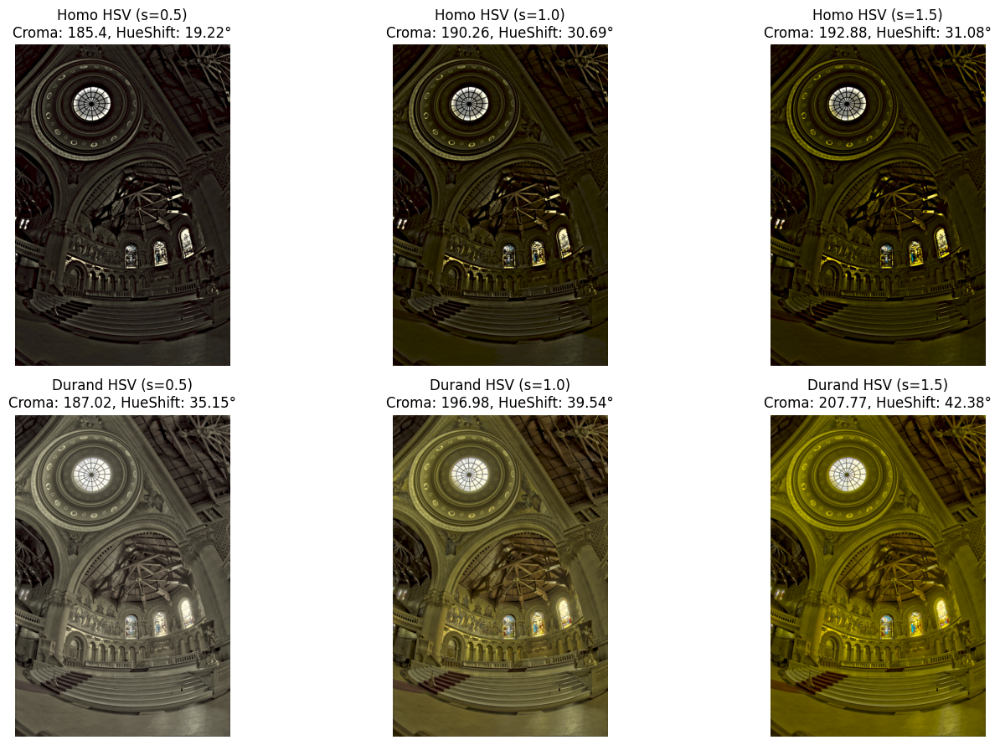

In [84]:
s_factors = [0.5, 1.0, 1.5]

fig, axs = plt.subplots(2, 3, figsize=(15, 9))
print("=== ESTRATEGIA 2: AJUSTE DE SATURACIÓN EN HSV (MEMORIAL) ===")
for idx, sf in enumerate(s_factors):
    rec_hsv_h = p2.reconstruct_color_hsv(img2_hdr, Y2_homo, s_factor=sf)
    m_h = p2.calculate_color_metrics(img2_hdr, rec_hsv_h)
    
    rec_hsv_d = p2.reconstruct_color_hsv(img2_hdr, Y2_durand, s_factor=sf)
    m_d = p2.calculate_color_metrics(img2_hdr, rec_hsv_d)
    
    print(f"s_factor = {sf:.1f} | Homo   - Croma: {m_h['chroma_proc']} | Hue Shift: {m_h['hue_shift_deg']}°")
    print(f"s_factor = {sf:.1f} | Durand - Croma: {m_d['chroma_proc']} | Hue Shift: {m_d['hue_shift_deg']}°")
    
    axs[0, idx].imshow(rec_hsv_h)
    axs[0, idx].set_title(f'Homo HSV (s={sf})\nCroma: {m_h["chroma_proc"]}, HueShift: {m_h["hue_shift_deg"]}°')
    axs[0, idx].axis('off')
    
    axs[1, idx].imshow(rec_hsv_d)
    axs[1, idx].set_title(f'Durand HSV (s={sf})\nCroma: {m_d["chroma_proc"]}, HueShift: {m_d["hue_shift_deg"]}°')
    axs[1, idx].axis('off')

plt.tight_layout()
plt.show()

Comparación: Estrategia 2 (Espacio HSV) vs. Estrategia 1 (Razón $\beta$)

- **Preservación Estricta de Tono ($\Delta H$):** La Estrategia 1 ($\beta$) logra una menor variación angular ($\Delta H \approx 20^\circ - 25^\circ$) debido a que opera en el espacio lineal conservando la dirección exacta del vector de cromaticidad ($C/Y$). En la Estrategia 2 (HSV), el viraje de tono es mayor ($\Delta H \approx 30^\circ - 42^\circ$) por la no-linealidad del espacio HSV y los errores de cuantización al reconvertir a 8 bits.
- **Control de Saturación:** Mientras que variar $\beta$ escala la cromaticidad de forma suave y proporcional, incrementar $s_{\text{factor}} > 1.0$ en HSV aplica un estiramiento lineal sobre $S$ que puede provocar *clipping* cromático (colores sobresaturados) en zonas de altas luces.
- **Conclusión:** Ambas soluciones corrigen la distorsión masiva de la compresión RGB independiente, pero la **Estrategia 1 con $\beta \approx 1.0 - 1.1$** resulta superior en fidelidad de color y continuidad visual.

### 3. Recortes Ampliados
Extraemos recortes regionales de zonas con transiciones de luz y colores intensos para comparar artefactos y bordes.